# Лабораторная работа 1: «Метод обратного распространения ошибки»

В данном блокноте представлена реализация двухслойной полносвязной нейронной сети с использованием библиотеки NumPy для классификации рукописных цифр из набора данных MNIST.

In [26]:
from google.colab import drive

drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [27]:
import time
import numpy as np
import matplotlib.pyplot as plt
import os
import struct

## 1. Загрузка и предобработка данных MNIST

Предобработка включает:
1. Нормализацию значений пикселей к диапазону $[0, 1]$.
2. Разделение выборки на тренировочную (60 000 примеров) и тестовую (10 000 примеров).
3. Кодирование меток классов в формат **One-Hot Encoding**.

In [28]:
import os
import zipfile

ARCHIVE_PATH = '/content/drive/MyDrive/Datasets/MNIST/archive.zip'
DATA_DIR = '/content/MNIST'

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ARCHIVE_PATH, 'r') as archive:
    archive.extractall(DATA_DIR)

print("Архив распакован:", DATA_DIR)
print(os.listdir(DATA_DIR))

Архив распакован: /content/MNIST
['t10k-labels-idx1-ubyte', 'train-labels.idx1-ubyte', 't10k-labels.idx1-ubyte', 't10k-images-idx3-ubyte', 't10k-images.idx3-ubyte', 'train-labels-idx1-ubyte', 'train-images.idx3-ubyte', 'train-images-idx3-ubyte']


In [29]:
def load_idx_images(filepath):
    """Чтение IDX-файла с изображениями MNIST."""
    with open(filepath, 'rb') as f:
        magic, num_images, rows, cols = struct.unpack('>IIII', f.read(16))
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(num_images, rows * cols).astype(np.float32) / 255.0

def load_idx_labels(filepath):
    """Чтение IDX-файла с метками классов MNIST."""
    with open(filepath, 'rb') as f:
        magic, num_labels = struct.unpack('>II', f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8).astype(np.int64)


def find_file(base_dir, name):
    p = os.path.join(base_dir, name)
    return p

train_img_path = find_file(DATA_DIR, 'train-images.idx3-ubyte')
train_lbl_path = find_file(DATA_DIR, 'train-labels.idx1-ubyte')
test_img_path  = find_file(DATA_DIR, 't10k-images.idx3-ubyte')
test_lbl_path  = find_file(DATA_DIR, 't10k-labels.idx1-ubyte')

X_train = load_idx_images(train_img_path)
y_train = load_idx_labels(train_lbl_path)
X_test  = load_idx_images(test_img_path)
y_test  = load_idx_labels(test_lbl_path)

def to_one_hot(labels, num_classes=10):
    return np.eye(num_classes)[labels]

y_train_oh = to_one_hot(y_train, 10)
y_test_oh = to_one_hot(y_test, 10)

print("--- Размерности данных ---")
print(f"Количество примеров в обучающей выборке: {X_train.shape[0]}")
print(f"Количество примеров в тестовой выборке:  {X_test.shape[0]}")
print(f"Форма одного изображения (в виде вектора): {X_train[0].shape} (28x28 = 784)")
print(f"Форма одного изображения (в 2D):          {(28, 28)}")
print(f"Форма меток (числовая / One-Hot):         {y_train.shape} / {y_train_oh.shape}")

--- Размерности данных ---
Количество примеров в обучающей выборке: 60000
Количество примеров в тестовой выборке:  10000
Форма одного изображения (в виде вектора): (784,) (28x28 = 784)
Форма одного изображения (в 2D):          (28, 28)
Форма меток (числовая / One-Hot):         (60000,) / (60000, 10)


### Визуализация примеров из набора данных

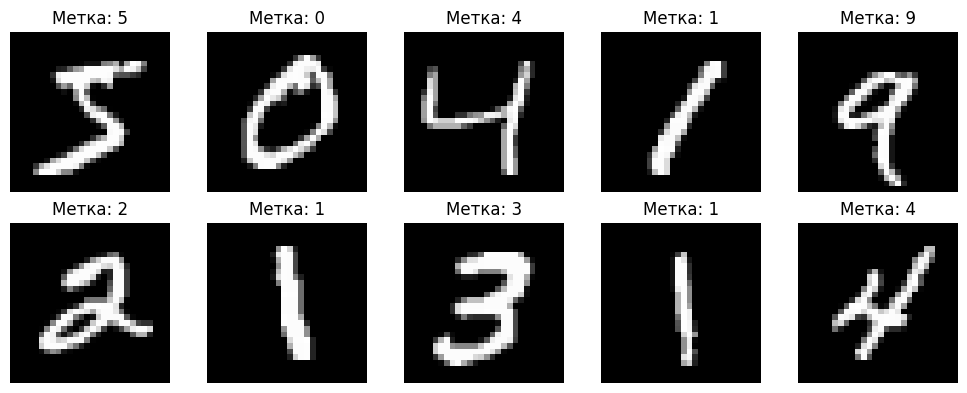

In [30]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Метка: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Реализация нейронной сети

In [31]:
class TwoLayerNet:
    def __init__(self, input_size=784, hidden_size=300, output_size=10, seed=42):
        np.random.seed(seed)
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))

        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

    def relu(self, z):
        return np.maximum(0, z)

    def softmax(self, z):
        shifted_z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(shifted_z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def forward(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self.relu(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.probs = self.softmax(self.Z2)
        return self.probs

    def compute_loss(self, probs, Y_oh):
        batch_size = Y_oh.shape[0]
        loss = -np.sum(Y_oh * np.log(probs + 1e-12)) / batch_size
        return loss

    def backward(self, Y_oh, learning_rate=0.1):
        batch_size = Y_oh.shape[0]

        dZ2 = (self.probs - Y_oh) / batch_size
        dW2 = self.A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * (self.Z1 > 0)
        dW1 = self.X.T @ dZ1
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def predict(self, X):
        probs = self.forward(X)
        return np.argmax(probs, axis=1)

## 3. Обучение нейронной сети на контрольных параметрах

Контрольные параметры согласно заданию:
- Размер пачки (`batch_size`): **32** (входит в диапазон от 8 до 64)
- Скорость обучения (`learning_rate`): **0.1**
- Количество скрытых нейронов (`s`): **300**
- Количество эпох (`epochs`): **20**

In [32]:
BATCH_SIZE = 32
LEARNING_RATE = 0.1
HIDDEN_NEURONS = 300
EPOCHS = 20

model = TwoLayerNet(input_size=784, hidden_size=HIDDEN_NEURONS, output_size=10)

num_samples = X_train.shape[0]
history_loss = []
history_error = []

print("Начало обучения...\n")
total_start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    indices = np.random.permutation(num_samples)
    X_shuffled = X_train[indices]
    y_shuffled_oh = y_train_oh[indices]

    for start_idx in range(0, num_samples, BATCH_SIZE):
        end_idx = start_idx + BATCH_SIZE
        X_batch = X_shuffled[start_idx:end_idx]
        y_batch = y_shuffled_oh[start_idx:end_idx]

        model.forward(X_batch)
        model.backward(y_batch, learning_rate=LEARNING_RATE)

    train_probs = model.forward(X_train)
    train_loss = model.compute_loss(train_probs, y_train_oh)
    train_preds = np.argmax(train_probs, axis=1)
    train_accuracy = np.mean(train_preds == y_train)
    train_error = (1.0 - train_accuracy) * 100

    epoch_time = time.time() - epoch_start
    history_loss.append(train_loss)
    history_error.append(train_error)

    print(f"Эпоха {epoch:2d}/{EPOCHS} | "
          f"Loss: {train_loss:.4f} | "
          f"Ошибка классификации (Train): {train_error:.2f}% (Точность: {train_accuracy*100:.2f}%) | "
          f"Время: {epoch_time:.2f} сек")

total_time = time.time() - total_start_time
print(f"\nОбучение завершено за {total_time:.2f} сек.")

Начало обучения...

Эпоха  1/20 | Loss: 0.1622 | Ошибка классификации (Train): 4.54% (Точность: 95.46%) | Время: 5.77 сек
Эпоха  2/20 | Loss: 0.0998 | Ошибка классификации (Train): 2.81% (Точность: 97.19%) | Время: 8.15 сек
Эпоха  3/20 | Loss: 0.0738 | Ошибка классификации (Train): 2.03% (Точность: 97.97%) | Время: 5.01 сек
Эпоха  4/20 | Loss: 0.0544 | Ошибка классификации (Train): 1.42% (Точность: 98.58%) | Время: 9.64 сек
Эпоха  5/20 | Loss: 0.0515 | Ошибка классификации (Train): 1.41% (Точность: 98.59%) | Время: 5.09 сек
Эпоха  6/20 | Loss: 0.0381 | Ошибка классификации (Train): 0.97% (Точность: 99.03%) | Время: 9.58 сек
Эпоха  7/20 | Loss: 0.0321 | Ошибка классификации (Train): 0.78% (Точность: 99.22%) | Время: 5.04 сек
Эпоха  8/20 | Loss: 0.0259 | Ошибка классификации (Train): 0.57% (Точность: 99.43%) | Время: 9.60 сек
Эпоха  9/20 | Loss: 0.0219 | Ошибка классификации (Train): 0.46% (Точность: 99.54%) | Время: 5.11 сек
Эпоха 10/20 | Loss: 0.0184 | Ошибка классификации (Train): 0.3

## 4. Оценка на тестовом наборе данных

In [33]:
test_probs = model.forward(X_test)
test_loss = model.compute_loss(test_probs, y_test_oh)
test_preds = np.argmax(test_probs, axis=1)

test_accuracy = np.mean(test_preds == y_test)
test_error = (1.0 - test_accuracy) * 100

print("=== Итоговые результаты на тестовой выборке ===")
print(f"Значение функции потерь (Test Cross-Entropy Loss): {test_loss:.4f}")
print(f"Ошибка классификации на тесте (Classification Error): {test_error:.2f}%")
print(f"Точность классификации на тесте (Test Accuracy):      {test_accuracy * 100:.2f}%")

=== Итоговые результаты на тестовой выборке ===
Значение функции потерь (Test Cross-Entropy Loss): 0.0614
Ошибка классификации на тесте (Classification Error): 1.82%
Точность классификации на тесте (Test Accuracy):      98.18%


### График обучения и примеры предсказаний

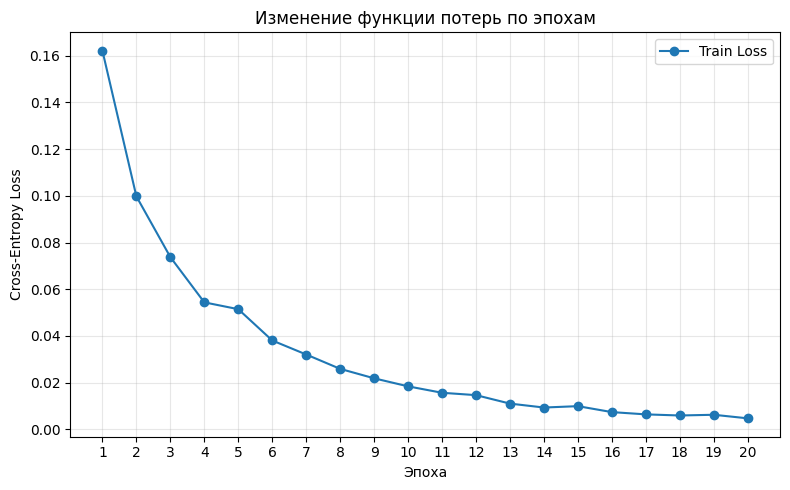

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    history_loss,
    marker='o',
    label='Train Loss'
)

plt.title('Изменение функции потерь по эпохам')
plt.xlabel('Эпоха')
plt.ylabel('Cross-Entropy Loss')
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

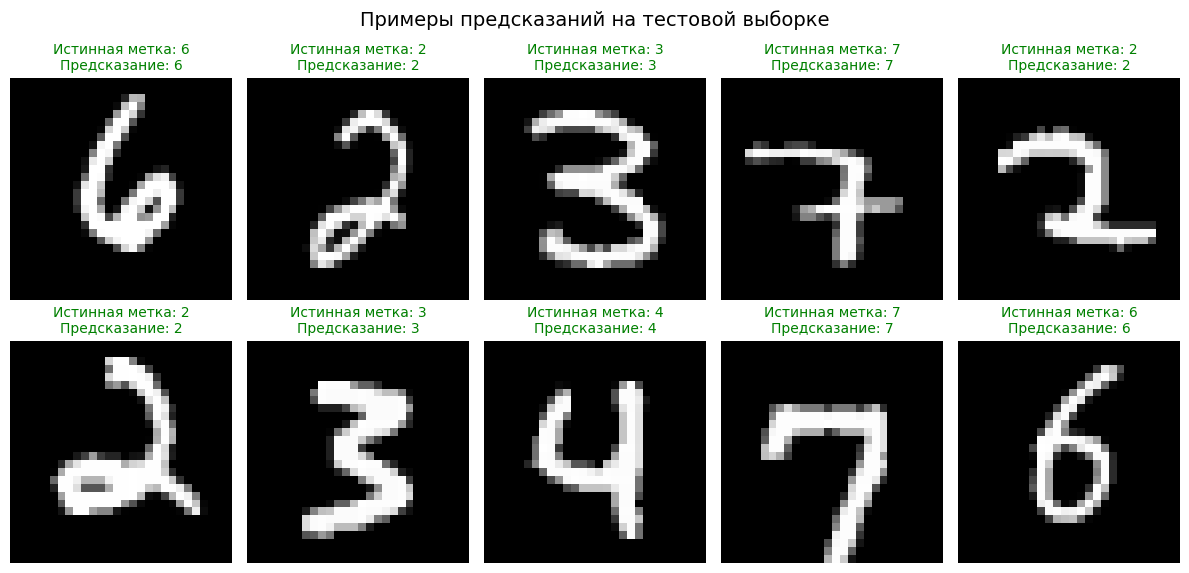

In [36]:
np.random.seed(42)
sample_indices = np.random.choice(len(X_test), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):
    image = X_test[idx].reshape(28, 28)
    true_label = y_test[idx]
    predicted_label = test_preds[idx]

    is_correct = true_label == predicted_label

    ax.imshow(image, cmap='gray')
    ax.set_title(
        f'Истинная метка: {true_label}\n'
        f'Предсказание: {predicted_label}',
        color='green' if is_correct else 'red',
        fontsize=10
    )
    ax.axis('off')

plt.suptitle('Примеры предсказаний на тестовой выборке', fontsize=14)
plt.tight_layout()
plt.show()
